In [1]:

!pip install -q xgboost


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Download Ames Housing dataset directly from OpenML

housing = fetch_openml(
    data_id=42165,
    as_frame=True,
    parser="auto"
)

# Features
X = housing.data.copy()

# Target
y = pd.to_numeric(housing.target, errors="coerce")

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")

# Remove rows with missing target values
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Target variable:", housing.target.name)

display(X.head())


Dataset loaded successfully!
Dataset shape: (1460, 80)
Target variable: SalePrice


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal


In [4]:

# Remove ID column if it exists
if "Id" in X.columns:
    X = X.drop(columns=["Id"])

# Identify numeric and categorical features
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nTarget variable: SalePrice")
print("Total records:", len(X))


Numeric features: 36
Categorical features: 43

Target variable: SalePrice
Total records: 1460


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1168
Testing samples: 292


In [6]:

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)


Preprocessing completed!
Training shape: (1168, 286)
Testing shape: (292, 286)


In [7]:

y_train_log = np.log1p(y_train)

print("Target transformation completed!")


Target transformation completed!


In [8]:

models = {

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    )
}

# Store predictions
predictions = {}

# Train models
for name, model in models.items():

    model.fit(
        X_train_processed,
        y_train_log
    )

    pred_log = model.predict(
        X_test_processed
    )

    # Convert predictions to original house prices
    predictions[name] = np.maximum(
        np.expm1(pred_log),
        0
    )

    print(name, "completed successfully!")


Linear Regression completed successfully!
Decision Tree completed successfully!
Random Forest completed successfully!
XGBoost completed successfully!
KNN completed successfully!


In [9]:

# Set random seeds
tf.random.set_seed(42)
np.random.seed(42)

# Create Neural Network
neural_model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(X_train_processed.shape[1],)
    ),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(64, activation="relu"),

    tf.keras.layers.Dense(32, activation="relu"),

    tf.keras.layers.Dense(1)
])

# Optimizer and loss
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

loss_function = tf.keras.losses.MeanSquaredError()

# Convert training data to NumPy arrays
X_nn = X_train_processed.astype("float32")

y_nn = y_train_log.to_numpy(
).reshape(-1, 1).astype("float32")

# Training settings
epochs = 100
batch_size = 32

# Backpropagation training loop
for epoch in range(epochs):

    # Shuffle training data
    indices = np.random.permutation(len(X_nn))

    epoch_losses = []

    for start in range(0, len(X_nn), batch_size):

        batch_indices = indices[start:start + batch_size]

        batch_X = tf.convert_to_tensor(
            X_nn[batch_indices]
        )

        batch_y = tf.convert_to_tensor(
            y_nn[batch_indices]
        )

        # 1. Forward propagation
        with tf.GradientTape() as tape:

            output = neural_model(
                batch_X,
                training=True
            )

            # 2. Calculate loss
            loss = loss_function(
                batch_y,
                output
            )

        # 3. Backpropagation
        gradients = tape.gradient(
            loss,
            neural_model.trainable_variables
        )

        # 4. Update weights and biases
        optimizer.apply_gradients(
            zip(
                gradients,
                neural_model.trainable_variables
            )
        )

        epoch_losses.append(float(loss.numpy()))

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"Loss: {np.mean(epoch_losses):.4f}"
        )

# Predict test data
nn_predictions_log = neural_model.predict(
    X_test_processed.astype("float32"),
    verbose=0
).flatten()

# Convert predictions back to original prices
predictions["Neural Network"] = np.maximum(
    np.expm1(nn_predictions_log),
    0
)

print("Neural Network with Backpropagation completed!")


Epoch 10/100 Loss: 0.0308
Epoch 20/100 Loss: 0.0125
Epoch 30/100 Loss: 0.0074
Epoch 40/100 Loss: 0.0074
Epoch 50/100 Loss: 0.0058
Epoch 60/100 Loss: 0.0356
Epoch 70/100 Loss: 0.0033
Epoch 80/100 Loss: 0.0128
Epoch 90/100 Loss: 0.0022
Epoch 100/100 Loss: 0.0033
Neural Network with Backpropagation completed!


In [10]:

results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    mse = mean_squared_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        y_pred
    )

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(
    results_df.style.format({
        "MAE": "{:,.2f}",
        "MSE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "R2 Score": "{:.4f}"
    })
)


,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Regression,"14,857.16","516,697,679.12","22,730.99",0.9326
1,XGBoost,"16,306.91","773,341,184.00","27,809.01",0.8992
2,Random Forest,"17,405.77","874,905,852.63","29,578.81",0.8859
3,Neural Network,"22,924.93","1,441,137,280.00","37,962.31",0.8121
4,KNN,"22,184.69","1,492,016,093.69","38,626.62",0.8055
5,Decision Tree,"25,348.60","1,519,183,136.18","38,976.70",0.8019


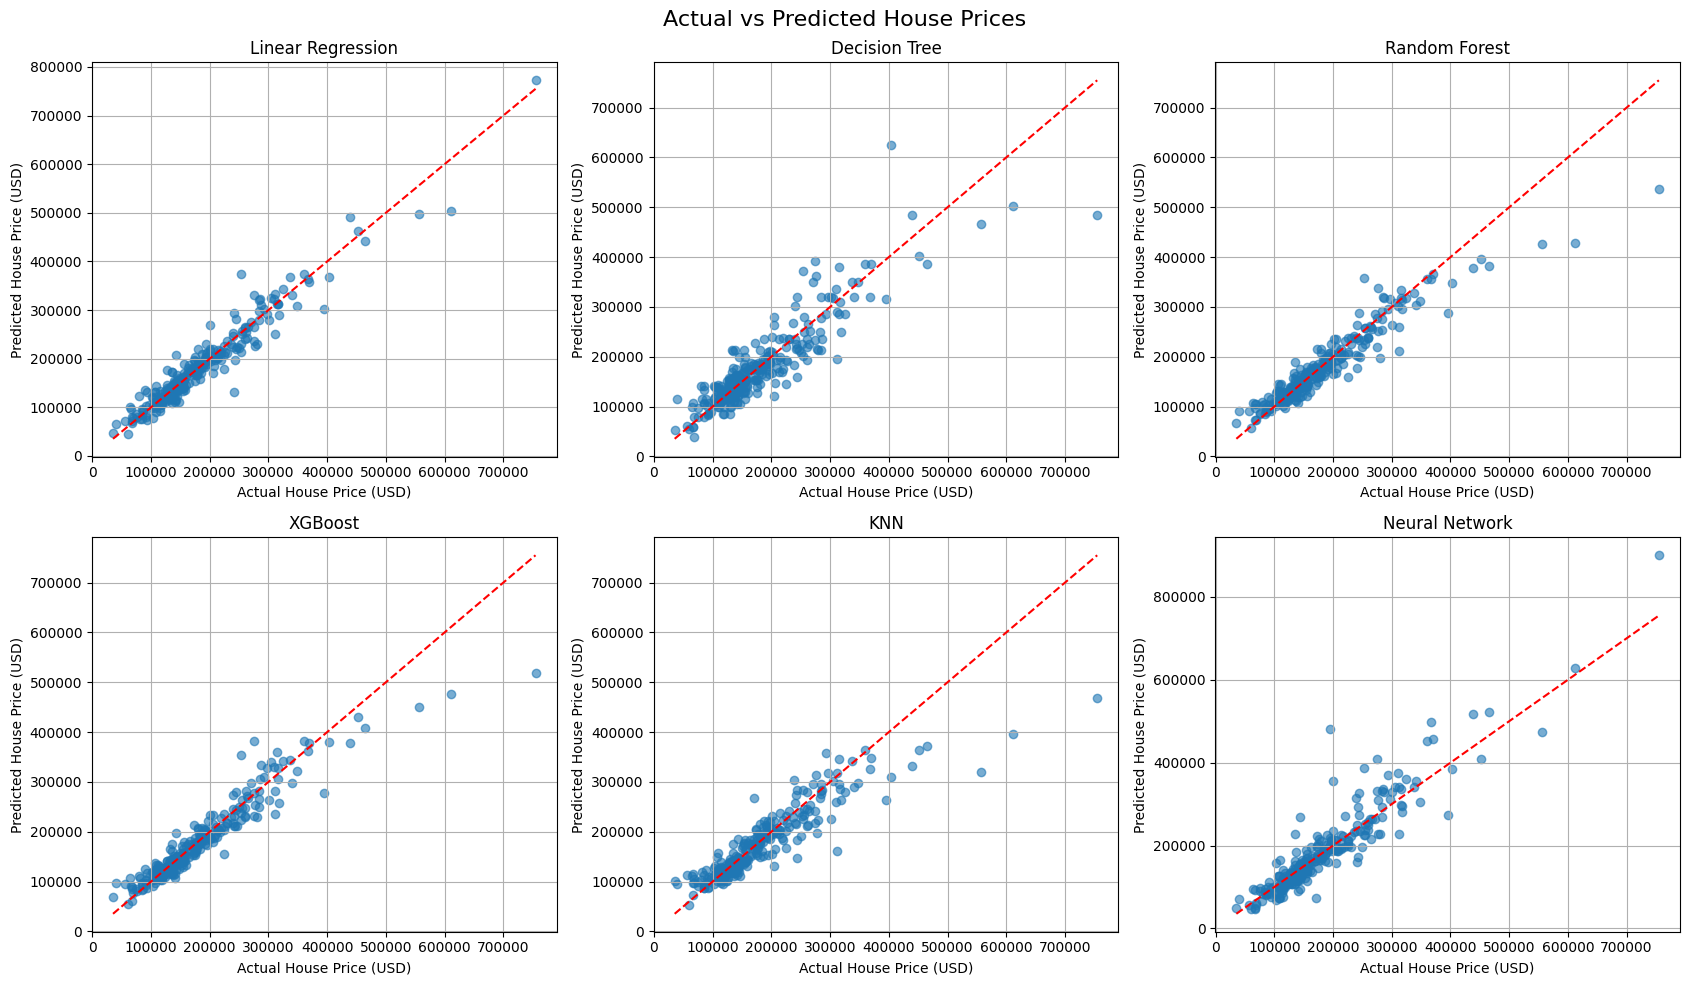

In [11]:

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

axes = axes.flatten()

actual_min = float(y_test.min())
actual_max = float(y_test.max())

for i, (name, y_pred) in enumerate(predictions.items()):

    axes[i].scatter(
        y_test,
        y_pred,
        alpha=0.6
    )

    axes[i].plot(
        [actual_min, actual_max],
        [actual_min, actual_max],
        "r--"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Actual House Price (USD)")
    axes[i].set_ylabel("Predicted House Price (USD)")
    axes[i].grid(True)

plt.suptitle(
    "Actual vs Predicted House Prices",
    fontsize=16
)

plt.tight_layout()
plt.show()


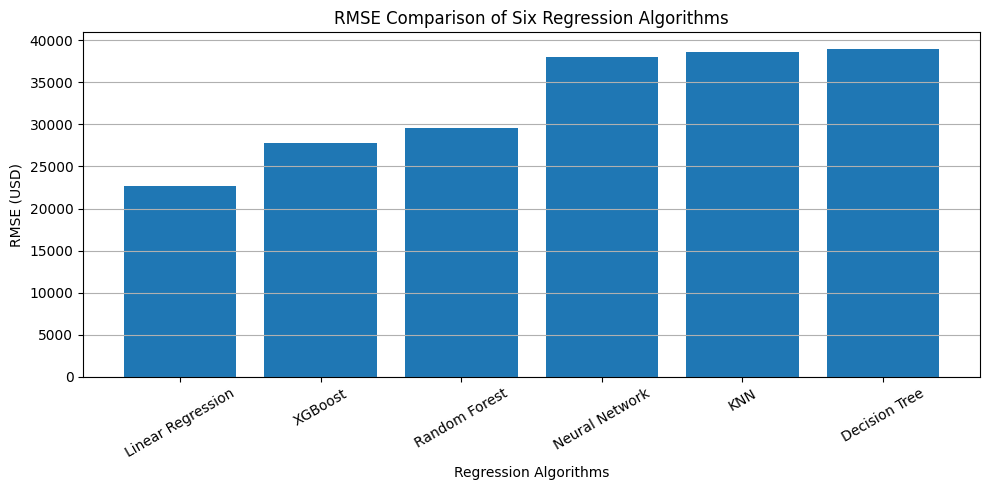

In [12]:

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Algorithm"],
    results_df["RMSE"]
)

plt.title("RMSE Comparison of Six Regression Algorithms")
plt.xlabel("Regression Algorithms")
plt.ylabel("RMSE (USD)")

plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [13]:

best_model = results_df.iloc[0]

print("BEST PERFORMING REGRESSION MODEL")
print("--------------------------------")

print("Algorithm:", best_model["Algorithm"])
print("MAE:", round(best_model["MAE"], 2))
print("MSE:", round(best_model["MSE"], 2))
print("RMSE:", round(best_model["RMSE"], 2))
print("R2 Score:", round(best_model["R2 Score"], 4))


BEST PERFORMING REGRESSION MODEL
--------------------------------
Algorithm: Linear Regression
MAE: 14857.16
MSE: 516697679.12
RMSE: 22730.99
R2 Score: 0.9326


In [14]:

results_df.to_csv(
    "House_Price_Regression_Results.csv",
    index=False
)

from google.colab import files

files.download(
    "House_Price_Regression_Results.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Loading Ames Housing dataset...
Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
XGBoost trained successfully!
KNN trained successfully!
Epoch 10/100 - Loss: 0.0306
Epoch 20/100 - Loss: 0.0119
Epoch 30/100 - Loss: 0.0073
Epoch 40/100 - Loss: 0.0057
Epoch 50/100 - Loss: 0.0053
Epoch 60/100 - Loss: 0.0048
Epoch 70/100 - Loss: 0.0108
Epoch 80/100 - Loss: 0.0117
Epoch 90/100 - Loss: 0.0057
Epoch 100/100 - Loss: 0.0055
Neural Network trained successfully!


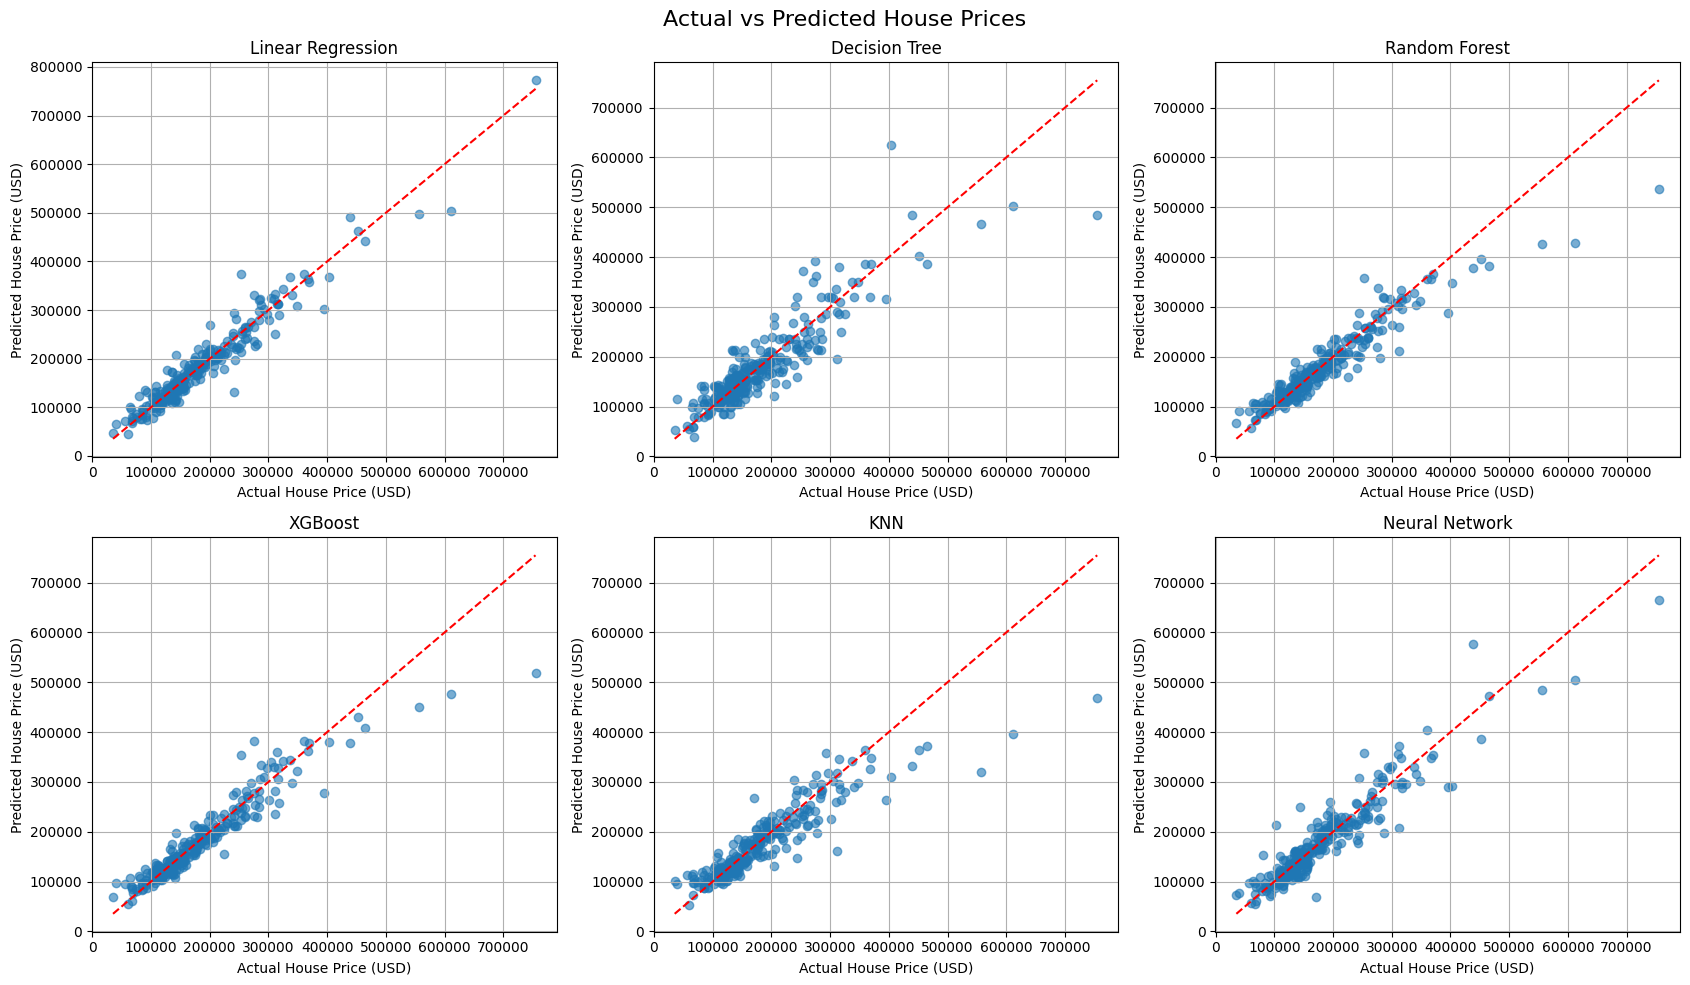


All data, metrics, sample predictions, and plots have been saved to 'ames_housing_results.md'!


In [15]:
# !pip install -q xgboost tabulate

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# ==========================================
# 1. LOAD & CLEAN DATASET
# ==========================================
print("Loading Ames Housing dataset...")
housing = fetch_openml(data_id=42165, as_frame=True, parser="auto")
X = housing.data.copy()
y = pd.to_numeric(housing.target, errors="coerce")

X = X.dropna(axis=1, how="all")
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

if "Id" in X.columns:
    X = X.drop(columns=["Id"])

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

# ==========================================
# 2. TRAIN-TEST SPLIT & PREPROCESSING
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
y_train_log = np.log1p(y_train)

# ==========================================
# 3. TRAIN TRADITIONAL ML MODELS
# ==========================================
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4,
        random_state=42, objective="reg:squarederror", n_jobs=-1
    ),
    "KNN": KNeighborsRegressor(n_neighbors=5)
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_processed, y_train_log)
    pred_log = model.predict(X_test_processed)
    predictions[name] = np.maximum(np.expm1(pred_log), 0)
    print(f"{name} trained successfully!")

# ==========================================
# 4. TRAIN NEURAL NETWORK (BACKPROPAGATION)
# ==========================================
tf.random.set_seed(42)
np.random.seed(42)

neural_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_processed.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
loss_function = tf.keras.losses.MeanSquaredError()

X_nn = X_train_processed.astype("float32")
y_nn = y_train_log.to_numpy().reshape(-1, 1).astype("float32")

epochs = 100
batch_size = 32
nn_training_logs = []

for epoch in range(epochs):
    indices = np.random.permutation(len(X_nn))
    epoch_losses = []
    for start in range(0, len(X_nn), batch_size):
        batch_indices = indices[start:start + batch_size]
        batch_X = tf.convert_to_tensor(X_nn[batch_indices])
        batch_y = tf.convert_to_tensor(y_nn[batch_indices])

        with tf.GradientTape() as tape:
            output = neural_model(batch_X, training=True)
            loss = loss_function(batch_y, output)

        gradients = tape.gradient(loss, neural_model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, neural_model.trainable_variables))
        epoch_losses.append(float(loss.numpy()))

    if (epoch + 1) % 10 == 0:
        log_msg = f"Epoch {epoch + 1}/{epochs} - Loss: {np.mean(epoch_losses):.4f}"
        print(log_msg)
        nn_training_logs.append({"Epoch": epoch + 1, "MSE Loss (Log)": round(np.mean(epoch_losses), 4)})

nn_predictions_log = neural_model.predict(X_test_processed.astype("float32"), verbose=0).flatten()
predictions["Neural Network"] = np.maximum(np.expm1(nn_predictions_log), 0)
print("Neural Network trained successfully!")

# ==========================================
# 5. EVALUATE & COMPARE MODELS
# ==========================================
results = []
for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results.append({
        "Algorithm": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values(by="RMSE", ascending=True).reset_index(drop=True)

# Format results for display and markdown
formatted_results_df = results_df.copy()
formatted_results_df["MAE"] = formatted_results_df["MAE"].map("{:,.2f}".format)
formatted_results_df["MSE"] = formatted_results_df["MSE"].map("{:,.2f}".format)
formatted_results_df["RMSE"] = formatted_results_df["RMSE"].map("{:,.2f}".format)
formatted_results_df["R2 Score"] = formatted_results_df["R2 Score"].map("{:.4f}".format)

# ==========================================
# 6. GENERATE & SAVE VISUALIZATION
# ==========================================
plot_filename = "actual_vs_predicted_prices.png"
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

actual_min = float(y_test.min())
actual_max = float(y_test.max())

for i, (name, y_pred) in enumerate(predictions.items()):
    axes[i].scatter(y_test, y_pred, alpha=0.6)
    axes[i].plot([actual_min, actual_max], [actual_min, actual_max], "r--")
    axes[i].set_title(name)
    axes[i].set_xlabel("Actual House Price (USD)")
    axes[i].set_ylabel("Predicted House Price (USD)")
    axes[i].grid(True)

plt.suptitle("Actual vs Predicted House Prices", fontsize=16)
plt.tight_layout()
plt.savefig(plot_filename, dpi=300)
plt.show()

# ==========================================
# 7. EXPORT ALL DATA & RESULTS TO .MD FILE
# ==========================================
md_filename = "ames_housing_results.md"

# Sample predictions dataframe (First 15 test records)
sample_preds_df = pd.DataFrame({"Actual Price ($)": y_test.values[:15]})
for name in results_df["Algorithm"]:
    sample_preds_df[name] = predictions[name][:15]
for col in sample_preds_df.columns:
    sample_preds_df[col] = sample_preds_df[col].map("{:,.2f}".format)

md_content = f"""# Ames Housing Price Prediction — Experiment Report

## 1. Dataset & Preprocessing Summary
* **Dataset Source:** OpenML (ID: 42165 - Ames Housing)
* **Target Variable:** `SalePrice` (Log-transformed via `np.log1p` during training)
* **Total Valid Records:** {len(X)}
* **Features Breakdown:** {len(numeric_features)} Numeric features, {len(categorical_features)} Categorical features
* **Train / Test Split:** {X_train.shape[0]} Training samples (80%) / {X_test.shape[0]} Testing samples (20%)
* **Processed Feature Matrix Shape:** `{X_train_processed.shape[1]}` columns after Imputation, Scaling, and One-Hot Encoding

### Sample Raw Features (First 5 Rows, First 10 Columns)
{X.iloc[:5, :10].to_markdown()}

---

## 2. Model Performance Comparison
Models are ranked from lowest to highest Root Mean Squared Error (**RMSE**):

{formatted_results_df.to_markdown(index=False)}

---

## 3. Neural Network Training Progress
* **Architecture:** `Input({X_train_processed.shape[1]}) -> Dense(128, ReLU) -> Dense(64, ReLU) -> Dense(32, ReLU) -> Dense(1)`
* **Optimizer:** Adam (`lr=0.001`) | **Batch Size:** {batch_size} | **Epochs:** {epochs}

{pd.DataFrame(nn_training_logs).to_markdown(index=False)}

---

## 4. Sample Test Set Predictions (First 15 Houses)
{sample_preds_df.to_markdown(index=False)}

---

## 5. Actual vs. Predicted Visualizations
![Actual vs Predicted House Prices]({plot_filename})
"""

with open(md_filename, "w", encoding="utf-8") as f:
    f.write(md_content)

print(f"\nAll data, metrics, sample predictions, and plots have been saved to '{md_filename}'!")